In [29]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from prob_reco_sbi.flash import load, network_input

# Load the simulation data
path = Path("data/t2_full.h5")
if not path.exists():
    path = Path("../data/t2_full.h5")
data = load(path)

# True event parameters
E = data.truth.energy
x0 = data.truth.x
y0 = data.truth.y
r0 = np.hypot(x0, y0)

# Sensor observations
charge = data.response.charge
time_mean = data.response.time_mean
time_first = data.response.time_first

# Basic quantities
R = data.detector.radius
N, M = charge.shape
Q = charge.sum(axis=1)
Y = data.config.optics.light_yield

print("Events:", N)
print("Sensors:", M)
print("Charge shape:", charge.shape)
print("Mean time shape:", time_mean.shape)

Events: 50000
Sensors: 32
Charge shape: (50000, 32)
Mean time shape: (50000, 32)


In [21]:
def plot_binned(ax, x, y, bins):          #将数据按照 x 分成若干区间，计算每个区间内 y 的平均值和统计误差，最后绘制带误差棒的曲线。
    centers = 0.5 * (bins[:-1] + bins[1:])#计算每个区间的中心点
    indices = np.digitize(x, bins) - 1    #np.digitize() 可以判断数组里的每个值属于哪个区间
    indices[x == bins[-1]] = len(centers) - 1
    means = []
    errors = []
    for i in range(len(centers)):
        values = y[(indices == i) & np.isfinite(y)] #这里是按照 x 进行分箱，对 有限值的y 进行统计。
        if len(values) > 1:
            means.append(np.mean(values)) #计算平均值并存入means
            errors.append(
                np.std(values, ddof=1) / np.sqrt(len(values))
            )                            #计算标准差并存入errors
        else:
            means.append(np.nan)
            errors.append(np.nan)
    ax.errorbar(
        centers, means, yerr=errors,
        fmt="o-", capsize=3
    )#这个函数将平均值和误差棒一起画出来                                   
    #centers：横坐标为每个分箱的中心 #means：纵坐标为每个分箱的平均值 #yerr=errors：纵向误差棒的长度 #fmt="o-"：用圆点表示数据，并用线连接#capsize=3误差棒两端横线的大小
    ax.grid(alpha=0.25)

In [22]:
all_charges = charge.ravel() # All sensor charges #展平成一维数组
n_hit = hit.sum(axis=1) # 每个事件有多少传感器收到了事件 #计算第一个维度的平均值
f_empty = (charge == 0).mean(axis=1) # 每个事件中空传感器所占的比例

print(all_charges.shape)
print(n_hit.shape)
print(f_empty.shape)

(1600000,)
(50000,)
(50000,)


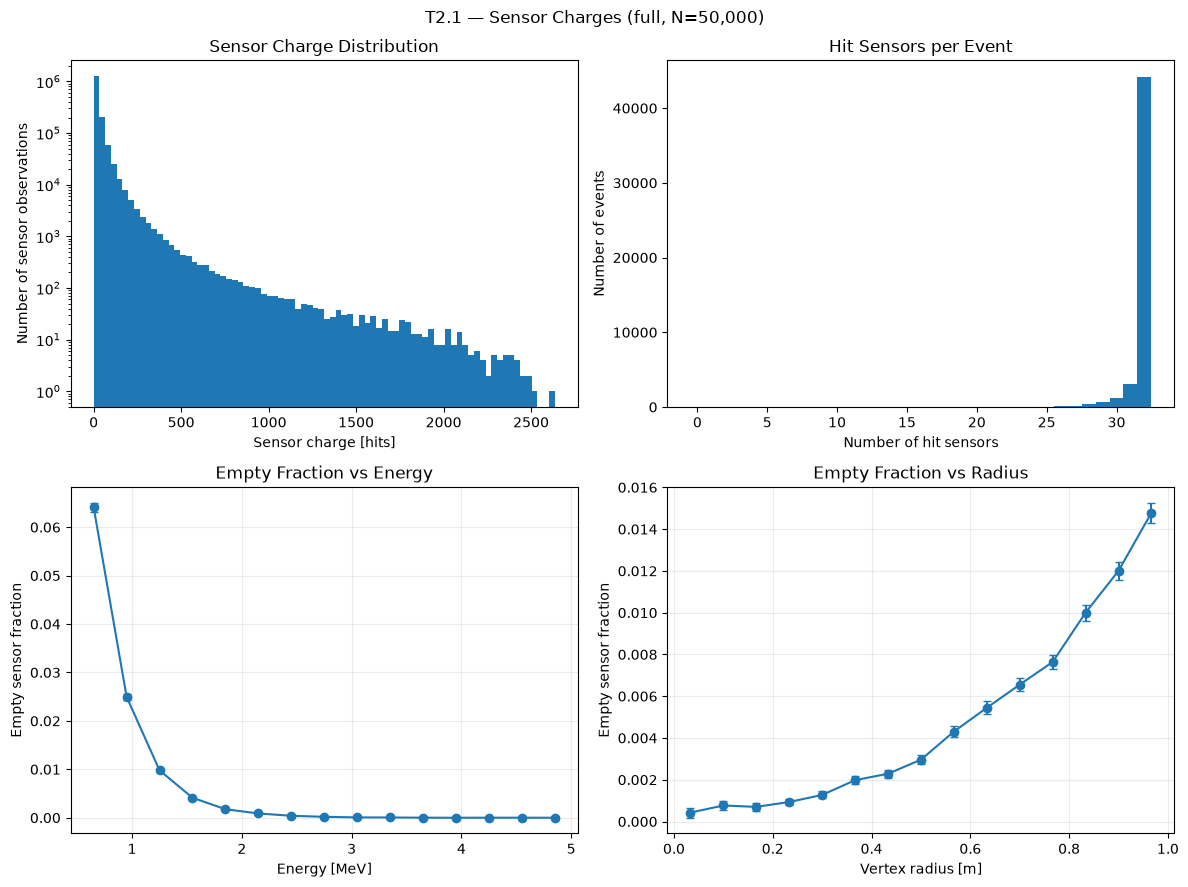

In [25]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

# 1. Distribution of sensor charges
ax[0, 0].hist(all_charges, bins=80, log=True)  #绘制直方图，bins=80 表示将数据的范围分成 80 个区间，统计每个区间内有多少。
ax[0, 0].set(
    xlabel="Sensor charge [hits]",
    ylabel="Number of sensor observations",
    title="Sensor Charge Distribution"
)
# 2. Number of hit sensors per event
ax[0, 1].hist(
    n_hit,
    bins=np.arange(-0.5, M + 1.5)
)
ax[0, 1].set(
    xlabel="Number of hit sensors",
    ylabel="Number of events",
    title="Hit Sensors per Event"
)
# 3. Empty fraction vs energy
plot_binned(
    ax[1, 0],
    E,
    f_empty,
    np.linspace(E.min(), E.max(), 16)
)
ax[1, 0].set(
    xlabel="Energy [MeV]",
    ylabel="Empty sensor fraction",
    title="Empty Fraction vs Energy"
)

# 4. Empty fraction vs vertex radius
plot_binned(
    ax[1, 1],
    r0,
    f_empty,
    np.linspace(0, R, 16)
)
ax[1, 1].set(
    xlabel="Vertex radius [m]",
    ylabel="Empty sensor fraction",
    title="Empty Fraction vs Radius"
)

fig.suptitle(f"T2.1 — Sensor Charges (full, N={N:,})")
plt.tight_layout()
plt.savefig("T2.1_sensor_charges.png", dpi=200)
plt.show()

In [26]:
light_collection = Q / (Y * E)

print("Mean total charge:", Q.mean())
print("Mean light collection:", light_collection.mean())

Mean total charge: 893.02686
Mean light collection: 0.32576458537416547


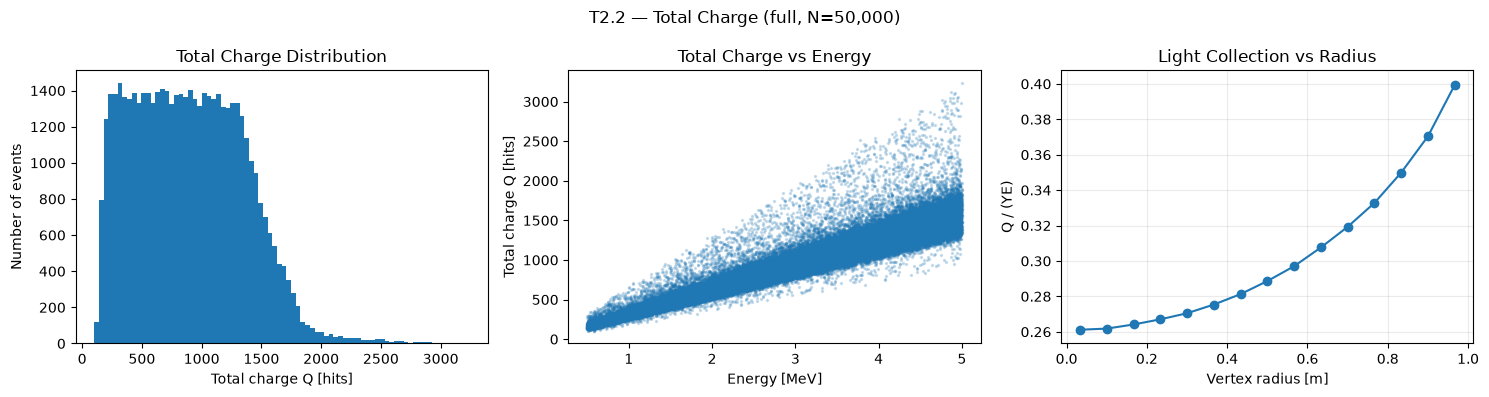

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# 1. Total charge distribution
ax[0].hist(Q, bins=80)
ax[0].set(
    xlabel="Total charge Q [hits]",
    ylabel="Number of events",
    title="Total Charge Distribution"
)
# 2. Total charge vs energy
ax[1].scatter(E, Q, s=2, alpha=0.2)
ax[1].set(
    xlabel="Energy [MeV]",
    ylabel="Total charge Q [hits]",
    title="Total Charge vs Energy"
)
# 3. Light collection vs radius
plot_binned(
    ax[2],
    r0,
    light_collection,
    np.linspace(0, R, 16)
)
ax[2].set(
    xlabel="Vertex radius [m]",
    ylabel="Q / (YE)",
    title="Light Collection vs Radius"
)

fig.suptitle(f"T2.2 — Total Charge (full, N={N:,})")
plt.tight_layout()
plt.savefig("T2.2_total_charge.png", dpi=200)
plt.show()

In [39]:
hit = charge > 0

valid_mean_times = time_mean[hit]
valid_first_times = time_first[hit]

In [40]:
X = network_input(charge, time_mean)#charge转换成log，tm转换成 relative time
relative_times = X[:, M:] #对NumPy 数组切片，选择32后面的所有列
log_charges = X[:, :M]

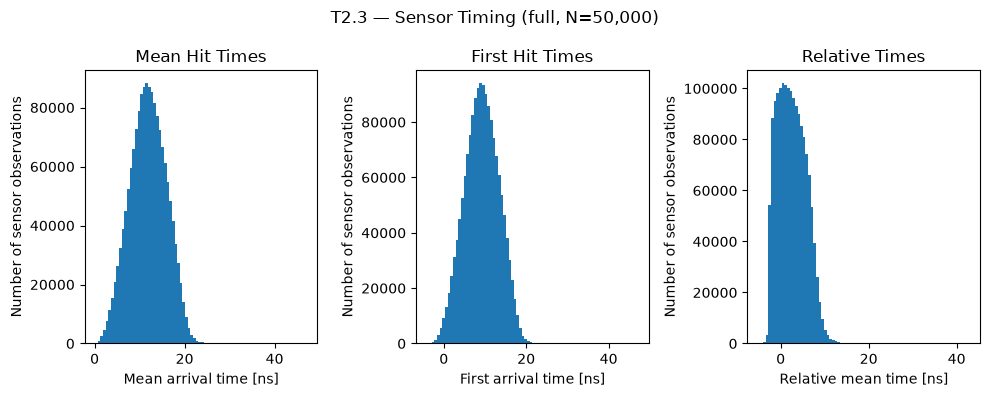

In [41]:
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
# Mean arrival times
ax[0].hist(time_mean[hit], bins=80) #绘制直方图，bins=80 表示将时间数据的范围分成 80 个区间，统计每个区间内有多少个传感器观测。
ax[0].set(
    xlabel="Mean arrival time [ns]",
    ylabel="Number of sensor observations",
    title="Mean Hit Times"
)
# First arrival times
ax[1].hist(time_first[hit], bins=80)
ax[1].set(
    xlabel="First arrival time [ns]",
    ylabel="Number of sensor observations",
    title="First Hit Times"
)
# Relative times
ax[2].hist(relative_times[hit], bins=80)
ax[2].set(
    xlabel="Relative mean time [ns]",
    ylabel="Number of sensor observations",
    title="Relative Times"
)

fig.suptitle(f"T2.3 — Sensor Timing (full, N={N:,})")
plt.tight_layout()
plt.savefig("T2.3_hit_times.png", dpi=200)
plt.show()

In [42]:
print("Input shape:", X.shape)
print("Log charge shape:", log_charges.shape)
print("Relative time shape:", relative_times.shape)
print("Number of NaNs:", np.isnan(X).sum())

Input shape: (50000, 64)
Log charge shape: (50000, 32)
Relative time shape: (50000, 32)
Number of NaNs: 0


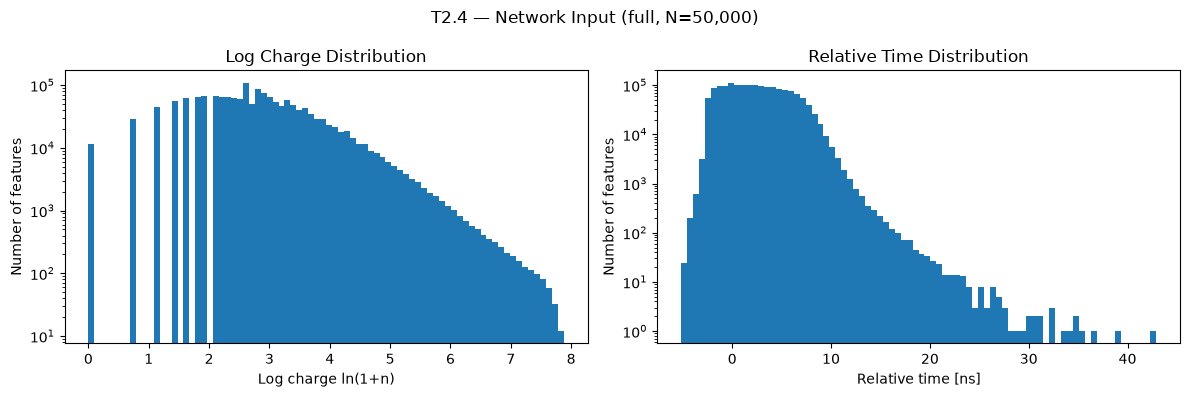

In [44]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Log charges
ax[0].hist(
    log_charges.ravel(),
    bins=80,
    log=True
)
ax[0].set(
    xlabel="Log charge ln(1+n)",
    ylabel="Number of features",
    title="Log Charge Distribution"
)
# Relative times
ax[1].hist(
    relative_times.ravel(),
    bins=80,
    log=True
)
ax[1].set(
    xlabel="Relative time [ns]",
    ylabel="Number of features",
    title="Relative Time Distribution"
)
fig.suptitle(f"T2.4 — Network Input (full, N={N:,})")
plt.tight_layout()
plt.savefig("T2.4_network_input.png", dpi=200)
plt.show()